<a href="https://colab.research.google.com/github/AHTISHAM327/gan-dcgan-reproduction/blob/main/rija_m1_2_data_checks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# M1-2 · Data checks (Rija)
Own MNIST Dataset (official files), splits, batch checks, labelled plot, train-only stats, CelebA shapes.

**Setup: code from GitHub + shared Drive**

In [1]:
import os, sys
os.environ['GIT_TERMINAL_PROMPT'] = '0'   # fail fast instead of asking for a password
REPO = '/content/gan-dcgan-reproduction'
if not os.path.exists(REPO):
    !git clone -q https://github.com/AHTISHAM327/gan-dcgan-reproduction.git {REPO}
else:
    !git -C {REPO} pull -q
assert os.path.exists(REPO), 'Could not download the repo: it must be Public (ask Ahtisham).'
need = ['__init__.py', 'losses.py', 'models.py', 'checks.py', 'evaluate.py', 'data.py', 'viz.py', 'train.py']
missing = [f for f in need if not os.path.exists(f'{REPO}/src/{f}')]
assert not missing, f'Not on GitHub yet: {missing}. Wait for the owner, then Runtime > Restart session > Run all.'
sys.path.insert(0, REPO)

from google.colab import drive
drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/gan-dcgan-reproduction-data'
assert os.path.exists(f'{DRIVE}/data/mnist'), 'Shared Drive folder not found: add a shortcut to it in My Drive.'
FIG = f'{DRIVE}/figures'
os.makedirs(FIG, exist_ok=True)
print('Code ready. Files in src:', sorted(os.listdir(f'{REPO}/src')))

Mounted at /content/drive
Code ready. Files in src: ['__init__.py', 'checks.py', 'data.py', 'evaluate.py', 'losses.py', 'models.py', 'train.py', 'viz.py']


**Our own MNIST Dataset and its 3 splits**

In [2]:
import torch
from src.data import MNISTFromIdx, make_loader, check_batch, compute_norm_stats, prepare_celeba, CelebAFaces
from src.viz import show_batch_with_labels
torch.manual_seed(42)

mnist_train = MNISTFromIdx(split='train')   # pixels in [0, 1] for the MLP GAN
mnist_valid = MNISTFromIdx(split='valid')
mnist_test  = MNISTFromIdx(split='test')
print('train', len(mnist_train), '| valid', len(mnist_valid), '| test', len(mnist_test))

train 50000 | valid 10000 | test 10000


**DataLoader + shape check**

In [3]:
train_loader = make_loader(mnist_train, batch_size=100)
x, y = check_batch(train_loader, expected_shape=(100, 1, 28, 28), expected_range=(0, 1))

images: (100, 1, 28, 28) torch.float32 | min 0.00 max 1.00
labels: (100,) torch.int64 | first 10: [7, 9, 6, 9, 3, 8, 6, 1, 6, 7]
OK: shape, dtype and range are correct


**One batch with its labels**

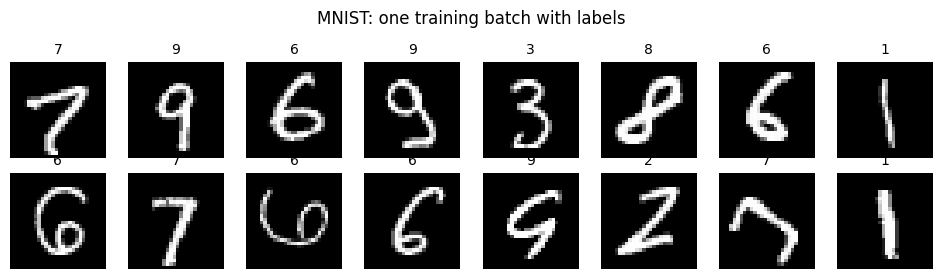

In [4]:
show_batch_with_labels(x, y, n=16, path=f'{FIG}/mnist_batch_labels.png',
                       title='MNIST: one training batch with labels')

**Mean and std from the training split only**

In [5]:
mean, std = compute_norm_stats(mnist_train)
print(f'MNIST train split (50,000 images): mean = {mean.item():.4f}, std = {std.item():.4f}')

MNIST train split (50,000 images): mean = 0.1310, std = 0.3085


We compute these on the training split only, so validation and test stay unseen. We do not standardise the images with them: the MLP generator ends in a sigmoid (outputs in 0–1), so real images must also be in 0–1, as in the GAN paper.

**CelebA: shapes only (no face pictures, because of the licence)**

In [6]:
img_dir, part_csv = prepare_celeba()          # copy + unzip from Drive, about 3-5 min
celeba_train = CelebAFaces(img_dir, part_csv, split=0)
print('CelebA train images:', len(celeba_train))
celeba_loader = make_loader(celeba_train, batch_size=128)
xc, _ = check_batch(celeba_loader, expected_shape=(128, 3, 64, 64), expected_range=(-1, 1))

CelebA train images: 162770
images: (128, 3, 64, 64) torch.float32 | min -1.00 max 1.00
labels: (128,) torch.int64 | first 10: [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1]
OK: shape, dtype and range are correct
